# Machine Learning Lab: Linear Regression

## Fish Market Dataset

**Objectives**

1. Implement Simple Linear Regression to predict a continuous value using a single feature.
2. Implement Multiple Linear Regression to predict a continuous value using multiple features.
3. Analyze and interpret the regression coefficients.
4. Evaluate the models using standard metrics such as Mean Squared Error (MSE) and R² Score.

**Dataset Source:** Kaggle, Fish Market Dataset  
https://www.kaggle.com/datasets/aungpyaeap/fish-market

**Note:** The uploaded `Fish.csv` is used as the working copy of the Kaggle dataset.

## 1. Import Libraries

The libraries below are used for data handling, visualization, model training, and evaluation.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## 2. Load the Dataset

The dataset contains physical measurements of fish. `Weight` is treated as the continuous target variable.

In [2]:
from pathlib import Path

# Kaggle notebooks: update this path if the dataset is attached under a different Kaggle input folder.
paths = list(Path("/kaggle/input").rglob("Fish.csv")) if Path("/kaggle/input").exists() else []

if paths:
    df = pd.read_csv(paths[0])
else:
    # Local execution fallback for the supplied working copy.
    df = pd.read_csv("Fish.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (159, 7)


,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


## 3. Initial Data Inspection

The first rows, data types, missing values, and duplicate rows are checked before modeling.

In [3]:
print("Data types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe())

Data types:


Species     object
Weight     float64
Length1    float64
Length2    float64
Length3    float64
Height     float64
Width      float64
dtype: object


Missing values:


Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64


Duplicate rows: 0

Summary statistics:


,Weight,Length1,Length2,Length3,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,26.247170,28.415723,31.227044,8.970994,4.417486
std,357.978317,9.996441,10.716328,11.610246,4.286208,1.685804
min,0.000000,7.500000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,19.050000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,25.200000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,32.700000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,59.000000,63.400000,68.000000,18.957000,8.142000


## 4. Data Preprocessing

`Weight` is the target. `Length2` is selected as the single feature for Simple Linear Regression because it provides a direct numerical predictor of fish weight.

For Multiple Linear Regression, the numerical physical measurements `Length1`, `Length2`, `Length3`, `Height`, and `Width` are used. `Species` is not included so that the experiment remains focused on numerical linear regression without categorical encoding.

In [4]:
target = "Weight"
simple_feature = ["Length2"]
multiple_features = ["Length1", "Length2", "Length3", "Height", "Width"]

X_simple = df[simple_feature]
X_multiple = df[multiple_features]
y = df[target]

X_simple_train, X_simple_test, y_simple_train, y_simple_test = train_test_split(
    X_simple, y, test_size=0.20, random_state=42
)

X_multiple_train, X_multiple_test, y_multiple_train, y_multiple_test = train_test_split(
    X_multiple, y, test_size=0.20, random_state=42
)

print("Training samples:", len(y_simple_train))
print("Testing samples:", len(y_simple_test))

Training samples: 127
Testing samples: 32


## 5. Simple Linear Regression

Simple Linear Regression models the relationship between one input feature and a continuous target:

$$y = b_0 + b_1x$$

where `b0` is the intercept and `b1` is the regression coefficient.

In [5]:
slr = LinearRegression()
slr.fit(X_simple_train, y_simple_train)

y_simple_pred = slr.predict(X_simple_test)

slr_mse = mean_squared_error(y_simple_test, y_simple_pred)
slr_r2 = r2_score(y_simple_test, y_simple_pred)

print("Intercept:", slr.intercept_)
print("Coefficient for Length2:", slr.coef_[0])
print("MSE:", slr_mse)
print("R2 Score:", slr_r2)

Intercept: -477.30634978973194
Coefficient for Length2: 30.434523940123125
MSE: 25604.524458494772
R2 Score: 0.8199897860284712


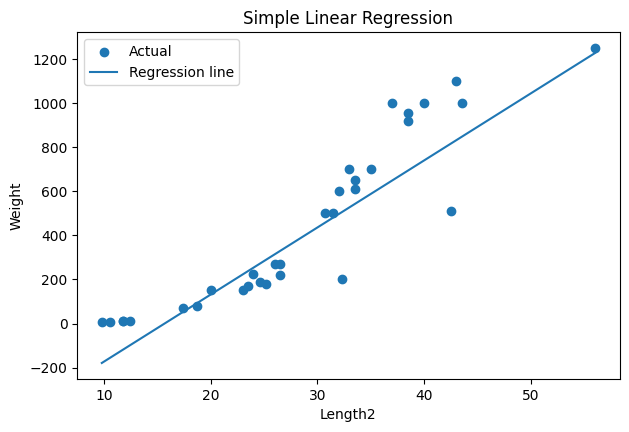

In [6]:
plt.figure(figsize=(7, 4.5))
plt.scatter(X_simple_test["Length2"], y_simple_test, label="Actual")

order = np.argsort(X_simple_test["Length2"].values)
plt.plot(
    X_simple_test["Length2"].values[order],
    y_simple_pred[order],
    label="Regression line"
)

plt.xlabel("Length2")
plt.ylabel("Weight")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

## 6. Multiple Linear Regression

Multiple Linear Regression extends the model to several input features:

$$y = b_0 + b_1x_1 + b_2x_2 + ... + b_nx_n$$

Each coefficient represents the expected change in the predicted target for a one-unit increase in that feature while the other included features are held constant.

In [7]:
mlr = LinearRegression()
mlr.fit(X_multiple_train, y_multiple_train)

y_multiple_pred = mlr.predict(X_multiple_test)

mlr_mse = mean_squared_error(y_multiple_test, y_multiple_pred)
mlr_r2 = r2_score(y_multiple_test, y_multiple_pred)

print("Intercept:", mlr.intercept_)
print("Coefficients:")
display(pd.Series(mlr.coef_, index=multiple_features, name="Coefficient"))

print("MSE:", mlr_mse)
print("R2 Score:", mlr_r2)

Intercept: -515.3056513384327
Coefficients:


Length1    43.535265
Length2     7.821796
Length3   -25.256701
Height     23.228912
Width      27.066493
Name: Coefficient, dtype: float64

MSE: 16763.88719314074
R2 Score: 0.8821430593048695


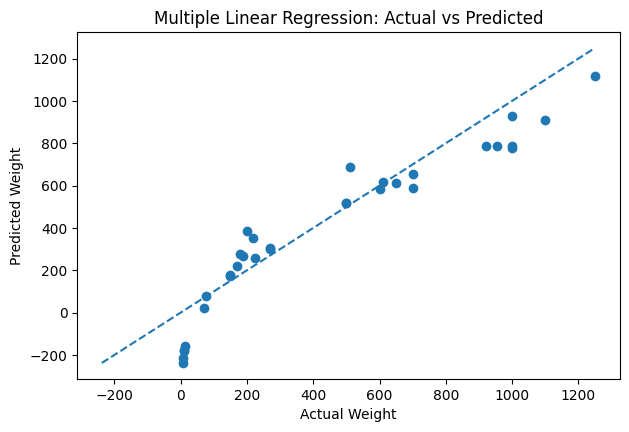

In [8]:
plt.figure(figsize=(7, 4.5))
plt.scatter(y_multiple_test, y_multiple_pred)

mn = min(y_multiple_test.min(), y_multiple_pred.min())
mx = max(y_multiple_test.max(), y_multiple_pred.max())
plt.plot([mn, mx], [mn, mx], linestyle="--")

plt.xlabel("Actual Weight")
plt.ylabel("Predicted Weight")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.show()

## 7. Model Comparison

MSE measures the average squared prediction error, so lower values indicate smaller errors.

R² measures the proportion of target variance explained by the model, with values closer to 1 indicating better fit.

In [9]:
comparison = pd.DataFrame({
    "Model": ["Simple Linear Regression", "Multiple Linear Regression"],
    "MSE": [slr_mse, mlr_mse],
    "R2 Score": [slr_r2, mlr_r2]
})

display(comparison)

,Model,MSE,R2 Score
0,Simple Linear Regression,25604.524458,0.819990
1,Multiple Linear Regression,16763.887193,0.882143


## 8. Coefficient Interpretation

### Simple Linear Regression

The `Length2` coefficient is positive. Therefore, within this fitted model, an increase of one unit in `Length2` is associated with an increase of approximately **30.43 units** in predicted weight.

### Multiple Linear Regression

The coefficients describe the fitted relationship while the other included predictors are held constant. Positive coefficients increase the predicted weight, while negative coefficients decrease it.

The signs and magnitudes should be interpreted in the context of the other correlated fish measurements. They are model coefficients, not independent causal effects.

In [10]:
coef_table = pd.DataFrame({
    "Feature": multiple_features,
    "Coefficient": mlr.coef_
})

display(coef_table)

,Feature,Coefficient
0,Length1,43.535265
1,Length2,7.821796
2,Length3,-25.256701
3,Height,23.228912
4,Width,27.066493


## 9. Key Findings

- Simple Linear Regression using `Length2` provides a strong baseline for predicting fish weight.
- Multiple Linear Regression achieves a lower MSE and higher R² on the same 80/20 train-test split.
- The Simple Linear Regression coefficient for `Length2` is positive, showing a positive fitted relationship between fish length and weight.
- The Multiple Linear Regression coefficients quantify the fitted contribution of the selected physical measurements while accounting for the other included features.
- The experiment demonstrates how adding relevant numerical features can improve prediction performance.

## 10. Learning Outcomes

After completing this experiment, the following concepts were demonstrated:

- Implementing Simple Linear Regression with one feature.
- Implementing Multiple Linear Regression with several features.
- Interpreting regression intercepts and coefficients.
- Splitting data into training and testing sets.
- Evaluating regression models using MSE and R² Score.
- Comparing a single-feature model with a multi-feature model.

## 11. Conclusion

Simple Linear Regression and Multiple Linear Regression were implemented on the Fish Market dataset to predict fish weight. The single-feature model established a clear baseline, while the multiple-feature model used several physical measurements and produced better test-set performance in this experiment. The regression coefficients were examined to understand the fitted relationships between the predictors and the target.